In [9]:
import pandas as pd
import os

# อ่านไฟล์ข้อมูล
file_path = "C:\\Users\\supin\\Downloads\\tourists_all(1)_cleaned.csv"
df = pd.read_csv(file_path)

# 1. ตรวจสอบขนาดข้อมูล
print("===== ขนาดข้อมูล =====")
print("จำนวนแถว:", df.shape[0])
print("จำนวนคอลัมน์:", df.shape[1])

# 2. ตรวจสอบชื่อคอลัมน์
print("\n===== ชื่อคอลัมน์ =====")
print(df.columns.tolist())

# 3. แสดงข้อมูล 5 แถวแรก
print("\n===== ตัวอย่างข้อมูล =====")
print(df.head())

# 4. ตรวจสอบชนิดข้อมูล
print("\n===== ชนิดข้อมูล =====")
print(df.dtypes)

# 5. ตรวจสอบค่าว่าง
print("\n===== จำนวนค่าว่าง =====")
print(df.isnull().sum())

# 6. ตรวจสอบข้อมูลซ้ำ
print("\n===== ข้อมูลซ้ำ =====")
print("จำนวนแถวซ้ำ:", df.duplicated().sum())

===== ขนาดข้อมูล =====
จำนวนแถว: 20316
จำนวนคอลัมน์: 5

===== ชื่อคอลัมน์ =====
['date', 'continent', 'Region', 'Country', 'Number']

===== ตัวอย่างข้อมูล =====
                  date continent              Region        Country Number
0  2015-01-01T00:00:00    Africa        North africa        Morocco    498
1  2015-01-01T00:00:00    Africa  Sub-Saharan Africa  South  Africa  5,154
2  2015-01-01T00:00:00    Africa  Sub-Saharan Africa       Ethiopia    621
3  2015-01-01T00:00:00    Africa  Sub-Saharan Africa          Kenya    357
4  2015-01-01T00:00:00    Africa  Sub-Saharan Africa      Mauritius    469

===== ชนิดข้อมูล =====
date         str
continent    str
Region       str
Country      str
Number       str
dtype: object

===== จำนวนค่าว่าง =====
date         0
continent    0
Region       0
Country      0
Number       0
dtype: int64

===== ข้อมูลซ้ำ =====
จำนวนแถวซ้ำ: 0


In [10]:
# 1. ตรวจสอบค่าที่อยู่ในคอลัมน์ Number
print(df["Number"].head(10))

# 2. ลบเครื่องหมายจุลภาคออก
df["Number"] = df["Number"].str.replace(",", "", regex=False)

# 3. เปลี่ยนเครื่องหมาย - เป็นค่าว่าง
df["Number"] = df["Number"].replace("-", pd.NA)

# 4. แปลงข้อมูลให้เป็นตัวเลข
df["Number"] = pd.to_numeric(df["Number"], errors="coerce")

# 5. ตรวจสอบผลลัพธ์
print("\n===== ผลหลังทำความสะอาด =====")
print(df["Number"].head(10))
print("\nชนิดข้อมูล:", df["Number"].dtype)
print("จำนวนค่า NaN:", df["Number"].isnull().sum())

0      498
1    5,154
2      621
3      357
4      469
5      182
6      394
7      385
8       57
9       31
Name: Number, dtype: str

===== ผลหลังทำความสะอาด =====
0     498
1    5154
2     621
3     357
4     469
5     182
6     394
7     385
8      57
9      31
Name: Number, dtype: int64

ชนิดข้อมูล: int64
จำนวนค่า NaN: 0


In [11]:
print(df["date"].iloc[100])
print(df["date"].iloc[500])
print(df["date"].iloc[1000])

2015-01-01T00:00:00
2015-01-03T00:00:00
2015-01-05T00:00:00


In [13]:
print(df["date"].tail(10))

20306    2023-01-12T00:00:00
20307    2023-01-12T00:00:00
20308    2023-01-12T00:00:00
20309    2023-01-12T00:00:00
20310    2023-01-12T00:00:00
20311    2023-01-12T00:00:00
20312    2023-01-12T00:00:00
20313    2023-01-12T00:00:00
20314    2023-01-12T00:00:00
20315    2023-01-12T00:00:00
Name: date, dtype: str


In [15]:
# แยกปี
df["Year"] = df["date"].str[:4].astype(int)

# แยกวันที่
df["Day"] = df["date"].str[5:7].astype(int)

# แยกเดือน
df["Month"] = df["date"].str[8:10].astype(int)

# สร้างไตรมาส
df["Quarter"] = ((df["Month"] - 1) // 3) + 1

# แสดงผลตรวจสอบ
print(df[["date", "Year", "Day", "Month", "Quarter"]].head())

                  date  Year  Day  Month  Quarter
0  2015-01-01T00:00:00  2015    1      1        1
1  2015-01-01T00:00:00  2015    1      1        1
2  2015-01-01T00:00:00  2015    1      1        1
3  2015-01-01T00:00:00  2015    1      1        1
4  2015-01-01T00:00:00  2015    1      1        1


In [18]:
print(df["Month"].value_counts().sort_index())

Month
1     1796
2     1781
3     1808
4     1606
5     1593
6     1598
7     1629
8     1582
9     1589
10    1745
11    1785
12    1804
Name: count, dtype: int64


In [20]:
# หาผลรวมนักท่องเที่ยวแยกตามปีและไตรมาส
quarter_total = df.groupby(
    ["Year", "Quarter"]
)["Number"].sum(min_count=1)

print(quarter_total)

Year  Quarter
2015  1           7833277
      2           6977875
      3           7275824
      4           7836209
2016  1           9004203
      2           7509900
      3           8249517
      4           7765968
2017  1           9181986
      2           8184984
      3           8887836
      4           9337172
2018  1          10578247
      2           8847205
      3           9042234
      4           9710508
2019  1          10792781
      2           9010224
      3           9705444
      4          10407802
2020  1           6691574
      4             33619
2021  1             38342
      2             34706
      3             65835
      4            371884
2022  1            488118
      2           1564658
      3           3582421
      4           5430029
2023  1           6528231
      2           6437153
      3           7089281
      4           8095351
Name: Number, dtype: int64


In [22]:
year_total = df.groupby("Year")["Number"].sum()

print(year_total)

Year
2015    29923185
2016    32529588
2017    35591978
2018    38178194
2019    39916251
2020     6725193
2021      510767
2022    11065226
2023    28150016
Name: Number, dtype: int64


In [24]:
quarter_count = quarter_total.groupby(level="Year").count()

print(quarter_count)

Year
2015    4
2016    4
2017    4
2018    4
2019    4
2020    2
2021    4
2022    4
2023    4
Name: Number, dtype: int64


In [26]:
# สร้างรายการไตรมาสที่ควรมี
expected_quarters = pd.MultiIndex.from_product(
    [range(2015, 2024), [1, 2, 3, 4]],
    names=["Year", "Quarter"]
)

# เปรียบเทียบกับไตรมาสที่มีอยู่จริง
missing_quarters = expected_quarters.difference(
    quarter_total.index
)

print(missing_quarters)

MultiIndex([(2020, 2),
            (2020, 3)],
           names=['Year', 'Quarter'])


In [28]:
# รวมยอดนักท่องเที่ยวรายปี
year_total = df.groupby("Year")["Number"].sum()

# สร้างตารางสำหรับวิเคราะห์โมเดล
df_year = year_total.reset_index()
df_year.columns = ["Year", "Tourists"]

print(df_year)

   Year  Tourists
0  2015  29923185
1  2016  32529588
2  2017  35591978
3  2018  38178194
4  2019  39916251
5  2020   6725193
6  2021    510767
7  2022  11065226
8  2023  28150016


In [30]:
# นับจำนวนไตรมาสที่มีข้อมูลในแต่ละปี
quarter_count = quarter_total.groupby(level="Year").count()

# เพิ่มจำนวนไตรมาสลงในตารางรายปี
df_year["Quarter_Count"] = (
    df_year["Year"].map(quarter_count)
)

print(df_year)

   Year  Tourists  Quarter_Count
0  2015  29923185              4
1  2016  32529588              4
2  2017  35591978              4
3  2018  38178194              4
4  2019  39916251              4
5  2020   6725193              2
6  2021    510767              4
7  2022  11065226              4
8  2023  28150016              4


In [32]:
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

# เลือกปีที่มีข้อมูลครบ 4 ไตรมาส
model_data = df_year[
    df_year["Quarter_Count"] == 4
].copy()

model_data = model_data.sort_values("Year").reset_index(drop=True)

results = []

# เริ่มทดสอบตั้งแต่ปี 2018
for i in range(3, len(model_data)):

    # ข้อมูลในอดีตก่อนปีที่ทดสอบ
    train = model_data.iloc[:i]

    # ปีที่ต้องการทดสอบ
    test = model_data.iloc[i]

    year = test["Year"]
    actual = test["Tourists"]

    # โมเดลที่ 1: Naive Forecast
    naive_pred = train["Tourists"].iloc[-1]

    # โมเดลที่ 2: ค่าเฉลี่ยของ 3 ปีที่มีข้อมูลล่าสุด
    ma_pred = train["Tourists"].tail(3).mean()

    # โมเดลที่ 3: Linear Regression
    model = LinearRegression()

    model.fit(
        train[["Year"]],
        train["Tourists"]
    )

    lr_pred = model.predict(
        pd.DataFrame({"Year": [year]})
    )[0]

    results.append({
        "Year": year,
        "Actual": actual,
        "Naive": naive_pred,
        "Moving_Average": ma_pred,
        "Linear_Regression": lr_pred
    })

comparison = pd.DataFrame(results)

print(comparison.round(0))

   Year    Actual     Naive  Moving_Average  Linear_Regression
0  2018  38178194  35591978      32681584.0         38350377.0
1  2019  39916251  38178194      35433253.0         41012590.0
2  2021    510767  39916251      37895474.0         45481734.0
3  2022  11065226    510767      26201737.0         12710877.0
4  2023  28150016  11065226      17164081.0          7884001.0


In [34]:
metrics = []

for name in [
    "Naive",
    "Moving_Average",
    "Linear_Regression"
]:
    error = comparison["Actual"] - comparison[name]

    mae = error.abs().mean()
    rmse = np.sqrt((error ** 2).mean())

    metrics.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

metrics_df = pd.DataFrame(metrics)

print(metrics_df.round(2))

               Model          MAE         RMSE
0              Naive  14273801.20  19828203.04
1     Moving_Average  14697352.27  18961703.89
2  Linear_Regression  13630231.02  22077314.33


In [37]:
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

# เลือกเฉพาะปีที่มีข้อมูลครบ 4 ไตรมาส
model_data = df_year[
    df_year["Quarter_Count"] == 4
].copy()

model_data = model_data.sort_values("Year").reset_index(drop=True)

results = []

# เริ่มทดสอบเมื่อมีข้อมูลอดีตอย่างน้อย 3 ปี
for i in range(3, len(model_data)):

    # ใช้เฉพาะข้อมูลก่อนปีที่ต้องการทำนาย
    train = model_data.iloc[:i]
    test = model_data.iloc[i]

    year = int(test["Year"])
    actual = test["Tourists"]

    # โมเดลที่ 1: Naive Forecast
    naive_pred = train["Tourists"].iloc[-1]

    # โมเดลที่ 2: Moving Average
    ma_pred = train["Tourists"].tail(3).mean()

    # โมเดลที่ 3: Linear Regression
    model = LinearRegression()
    model.fit(train[["Year"]], train["Tourists"])

    lr_pred = model.predict(
        pd.DataFrame({"Year": [year]})
    )[0]

    results.append({
        "Year": year,
        "Actual": actual,
        "Naive": naive_pred,
        "Moving_Average": ma_pred,
        "Linear_Regression": lr_pred
    })

comparison = pd.DataFrame(results)

print(comparison.round(0))

   Year    Actual     Naive  Moving_Average  Linear_Regression
0  2018  38178194  35591978      32681584.0         38350377.0
1  2019  39916251  38178194      35433253.0         41012590.0
2  2021    510767  39916251      37895474.0         45481734.0
3  2022  11065226    510767      26201737.0         12710877.0
4  2023  28150016  11065226      17164081.0          7884001.0


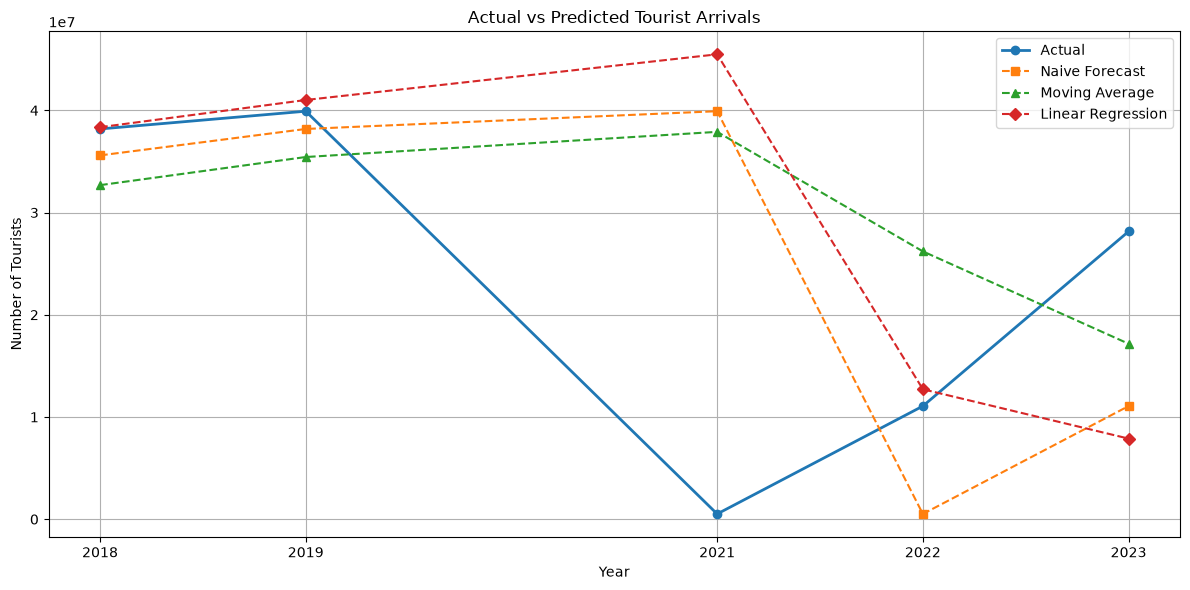

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# ค่าจริง
plt.plot(
    comparison["Year"],
    comparison["Actual"],
    marker="o",
    linewidth=2,
    label="Actual"
)

# ค่าพยากรณ์จาก Naive
plt.plot(
    comparison["Year"],
    comparison["Naive"],
    marker="s",
    linestyle="--",
    label="Naive Forecast"
)

# ค่าพยากรณ์จาก Moving Average
plt.plot(
    comparison["Year"],
    comparison["Moving_Average"],
    marker="^",
    linestyle="--",
    label="Moving Average"
)

# ค่าพยากรณ์จาก Linear Regression
plt.plot(
    comparison["Year"],
    comparison["Linear_Regression"],
    marker="D",
    linestyle="--",
    label="Linear Regression"
)

plt.xlabel("Year")
plt.ylabel("Number of Tourists")
plt.title("Actual vs Predicted Tourist Arrivals")
plt.legend()
plt.grid(True)
plt.xticks(comparison["Year"])
plt.tight_layout()
plt.show()

In [41]:
# คำนวณความคลาดเคลื่อนแบบค่าสัมบูรณ์
for name in [
    "Naive",
    "Moving_Average",
    "Linear_Regression"
]:
    comparison[name + "_Error"] = (
        comparison["Actual"] - comparison[name]
    ).abs()

print(comparison[[
    "Year",
    "Naive_Error",
    "Moving_Average_Error",
    "Linear_Regression_Error"
]].round(0))

   Year  Naive_Error  Moving_Average_Error  Linear_Regression_Error
0  2018      2586216             5496610.0                 172183.0
1  2019      1738057             4482998.0                1096340.0
2  2021     39405484            37384707.0               44970967.0
3  2022     10554459            15136511.0                1645651.0
4  2023     17084790            10985935.0               20266015.0


Intercept: 37042895.95116773
Slope: -2596063.309978769


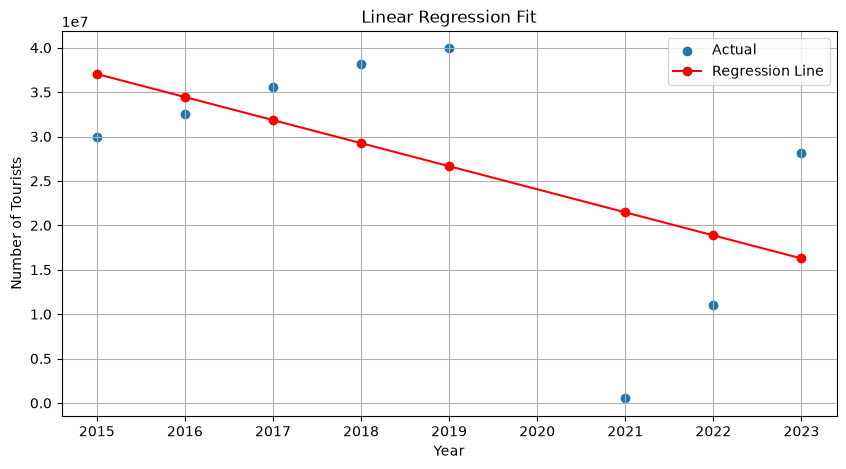

In [45]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# เปลี่ยนปีให้เริ่มนับจาก 0 ในปี 2015
model_data["Year_Index"] = model_data["Year"] - 2015

X = model_data[["Year_Index"]]
y = model_data["Tourists"]

# สร้างโมเดลจากข้อมูลครบชุด
model = LinearRegression()
model.fit(X, y)

print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])

# ค่าที่โมเดลประมาณจากข้อมูลแต่ละปี
model_data["Fitted"] = model.predict(X)

# กราฟค่าจริงและค่าที่โมเดลประมาณ
plt.figure(figsize=(10, 5))

plt.scatter(
    model_data["Year"],
    model_data["Tourists"],
    label="Actual"
)

plt.plot(
    model_data["Year"],
    model_data["Fitted"],
    color="red",
    marker="o",
    label="Regression Line"
)

plt.xlabel("Year")
plt.ylabel("Number of Tourists")
plt.title("Linear Regression Fit")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. รวมจำนวนนักท่องเที่ยวตามปีและไตรมาส
quarter_total = df.groupby(
    ["Year", "Quarter"]
)["Number"].sum(min_count=1).reset_index()

quarter_total = quarter_total.sort_values(
    ["Year", "Quarter"]
)

print(quarter_total.head())

   Year  Quarter   Number
0  2015        1  7833277
1  2015        2  6977875
2  2015        3  7275824
3  2015        4  7836209
4  2016        1  9004203


In [50]:
# สร้างวันที่รายไตรมาส
quarter_total["Period"] = pd.PeriodIndex(
    quarter_total["Year"].astype(str)
    + "Q"
    + quarter_total["Quarter"].astype(str),
    freq="Q"
)

quarter_total = quarter_total.set_index("Period").sort_index()

# 3. เติมช่วงไตรมาสที่ขาดให้ครบ โดยให้ค่าที่ยังไม่มีเป็น NaN
all_quarters = pd.period_range(
    start=quarter_total.index.min(),
    end=quarter_total.index.max(),
    freq="Q"
)

quarter_total = quarter_total.reindex(all_quarters)
quarter_total.index.name = "Period"

# 4. เพิ่มคอลัมน์ปีและไตรมาส
quarter_total["Year"] = quarter_total.index.year
quarter_total["Quarter"] = quarter_total.index.quarter

# 5. พยากรณ์จากไตรมาสเดียวกันของปีก่อน
quarter_total["Forecast"] = quarter_total["Number"].shift(4)

print(
    quarter_total[
        ["Year", "Quarter", "Number", "Forecast"]
    ].tail(12)
)

        Year  Quarter     Number   Forecast
Period                                     
2021Q1  2021        1    38342.0  6691574.0
2021Q2  2021        2    34706.0        NaN
2021Q3  2021        3    65835.0        NaN
2021Q4  2021        4   371884.0    33619.0
2022Q1  2022        1   488118.0    38342.0
2022Q2  2022        2  1564658.0    34706.0
2022Q3  2022        3  3582421.0    65835.0
2022Q4  2022        4  5430029.0   371884.0
2023Q1  2023        1  6528231.0   488118.0
2023Q2  2023        2  6437153.0  1564658.0
2023Q3  2023        3  7089281.0  3582421.0
2023Q4  2023        4  8095351.0  5430029.0


In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# เลือกข้อมูลสำหรับทดสอบ เฉพาะปี 2022–2023
result = quarter_total[
    (quarter_total["Year"] >= 2022) &
    (quarter_total["Year"] <= 2023)
].dropna(subset=["Number", "Forecast"]).copy()

# แสดงค่าจริงและค่าพยากรณ์
print(result[["Year", "Quarter", "Number", "Forecast"]])

# คำนวณความคลาดเคลื่อน
mae = mean_absolute_error(
    result["Number"],
    result["Forecast"]
)

rmse = np.sqrt(mean_squared_error(
    result["Number"],
    result["Forecast"]
))

print("\nจำนวนไตรมาสที่ใช้ทดสอบ =", len(result))
print("MAE =", round(mae, 2))
print("RMSE =", round(rmse, 2))

        Year  Quarter     Number   Forecast
Period                                     
2022Q1  2022        1   488118.0    38342.0
2022Q2  2022        2  1564658.0    34706.0
2022Q3  2022        3  3582421.0    65835.0
2022Q4  2022        4  5430029.0   371884.0
2023Q1  2023        1  6528231.0   488118.0
2023Q2  2023        2  6437153.0  1564658.0
2023Q3  2023        3  7089281.0  3582421.0
2023Q4  2023        4  8095351.0  5430029.0

จำนวนไตรมาสที่ใช้ทดสอบ = 8
MAE = 3454906.12
RMSE = 3874926.46
